In [1]:
from google.colab import drive

drive.mount('/content/drive')
BASE = "/content/drive/MyDrive/UTokyo/Proteome"

Mounted at /content/drive


# Secretome functional classes


Non-redundant secretome sizes (denominators):
  Spil  SP+:   406 proteins
  Spil  SP−:   115 proteins
  Snat  SP+:   983 proteins
  Snat  SP−:   274 proteins
  Stri  SP+:  1066 proteins
  Stri  SP−:   277 proteins
  Slin  SP+:   807 proteins
  Slin  SP−:   191 proteins
  Snec  SP+:   782 proteins
  Snec  SP−:   199 proteins
  Smic  SP+:   599 proteins
  Smic  SP−:   192 proteins
  Bmin  SP+:   752 proteins
  Bmin  SP−:   232 proteins

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/dbcan_merops_panel_grouped.{pdf,svg,png}


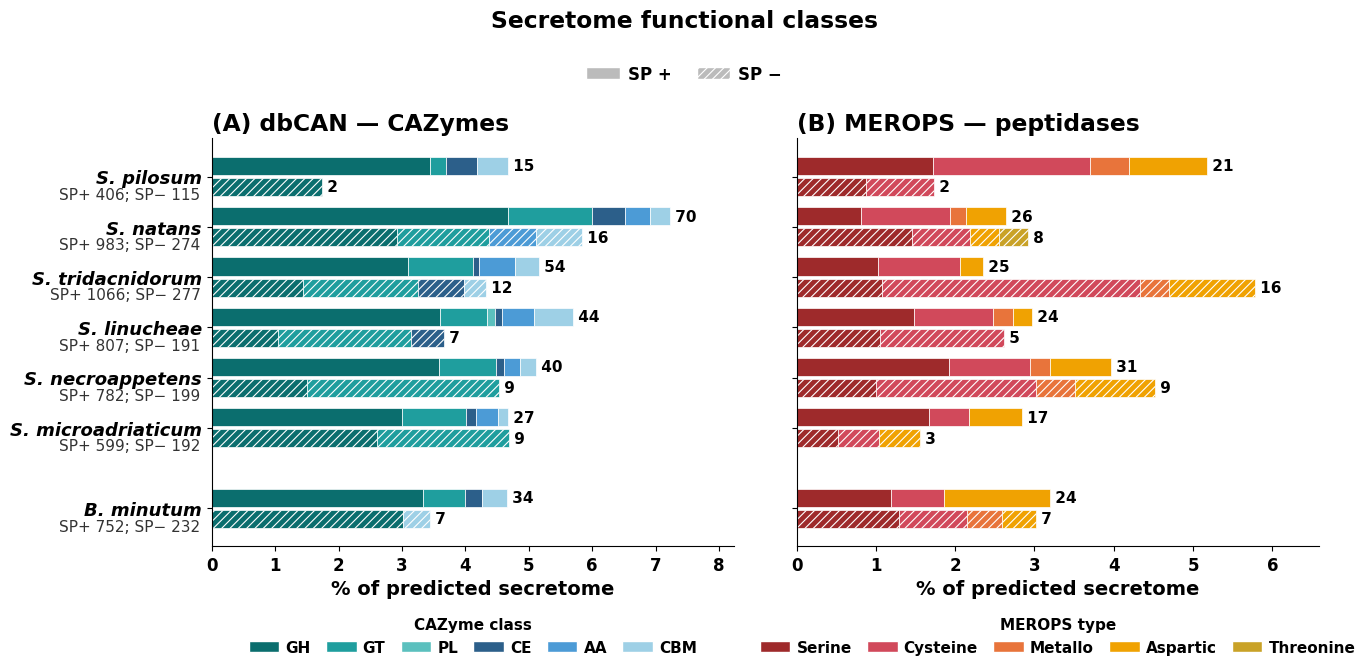

In [ ]:
# ============================================================
# dbCAN CAZymes + MEROPS peptidases — 1x2 horizontal panel
# x-axis = % of non-redundant secretome (denominator = uniInput size)
# Per species: two stacked bars (SP+ solid, SP− hatched)
# ============================================================
import os, re, glob
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Patch

DBCAN_DIR  = os.path.join(BASE, "12_db_functional_classes", "dbcan_out")
MEROPS_DIR = os.path.join(BASE, "12_db_functional_classes", "merops_out")
OUT_DIR    = os.path.join(BASE, "Publication", "figures_pre")
os.makedirs(OUT_DIR, exist_ok=True)

STRAIN_ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
KEEP = set(STRAIN_ORDER)
GENUS = {"Spil":"Symbiodinium","Snat":"Symbiodinium","Stri":"Symbiodinium",
         "Slin":"Symbiodinium","Snec":"Symbiodinium","Smic":"Symbiodinium",
         "Bmin":"Breviolum"}
SPECIES = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
           "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
           "Bmin":"B. minutum"}

CATS  = ["SP+","SP−"]
HATCH = {"SP+": "", "SP−": "////"}

def canon_strain(raw):
    if raw.startswith("Smic"): return "Smic"
    for s in STRAIN_ORDER:
        if raw == s or raw.startswith(s + "_") or raw.startswith(s): return s
    return raw

# ---------- dbCAN palette (cool) ----------
CAZY_CLASSES = ["GH","GT","PL","CE","AA","CBM"]
CLASS_COLOR  = {"GH":"#0B6E6E","GT":"#1F9E9E","PL":"#5BC0BE",
                "CE":"#2C5F8A","AA":"#4C9BD6","CBM":"#9ED0E6"}
CAZ_RE = re.compile(r'\b(GH|GT|PL|CE|AA|CBM)\d+')

# ---------- MEROPS palette (warm) ----------
CAT_TYPES = ["S","C","M","A","T","G","N","P","U","I"]
CAT_NAME  = {"S":"Serine","C":"Cysteine","M":"Metallo","A":"Aspartic","T":"Threonine",
             "G":"Glutamic","N":"Asparagine","P":"Mixed","U":"Unknown","I":"Inhibitor"}
CAT_COLOR = {"S":"#9E2A2B","C":"#D1495B","M":"#E8743B","A":"#F0A202","T":"#C9A227",
             "G":"#7B4B94","N":"#B08BBA","P":"#8C6A5D","U":"#C7B8A1","I":"#5C3A21"}
MER_RE = re.compile(r'\b([ASCGMNPTU]\d{2}\.\d{3})\b')

# ---------- helpers ----------
def count_fasta(path):
    n = 0
    with open(path) as fh:
        for line in fh:
            if line.startswith(">"): n += 1
    return n

def find_uniinput(folder):
    for pat in ("uniInput","uniInput.faa","uniInput.fasta","*uniInput*","*.faa"):
        hits = [h for h in glob.glob(os.path.join(folder, "**", pat), recursive=True)
                if os.path.isfile(h)]
        if hits: return sorted(hits, key=len)[0]
    return None

def find_overview(folder):
    for pat in ("overview.tsv","overview.txt","*overview*.tsv","*overview*.txt"):
        hits = glob.glob(os.path.join(folder, "**", pat), recursive=True)
        if hits: return sorted(hits)[0]
    return None

def parse_overview(path):
    df = pd.read_csv(path, sep="\t", dtype=str).fillna("")
    if df.shape[1] == 1: df = pd.read_csv(path, dtype=str).fillna("")
    cols = list(df.columns)
    gene_col   = next((c for c in cols if "gene" in c.lower()), cols[0])
    tool_cols  = [c for c in cols if c.lower().replace("-","_") in
                  ("hmmer","dbcan_sub","ecami","hotpep","diamond")]
    ntools_col = next((c for c in cols if "tool" in c.lower()), None)
    search_cols = tool_cols if tool_cols else [c for c in cols if c != gene_col]
    counts = {c: 0 for c in CAZY_CLASSES}; n_prot = 0
    for _, r in df.iterrows():
        if ntools_col:
            digits = re.sub(r"[^0-9]", "", str(r[ntools_col])); n = int(digits) if digits else 0
        else:
            n = sum(1 for c in tool_cols
                    if str(r[c]).strip() not in ("-","") and CAZ_RE.search(str(r[c])))
        if n < 2: continue
        classes = {m.group(1) for c in search_cols for m in CAZ_RE.finditer(str(r[c]))}
        if classes:
            n_prot += 1
            for c in classes: counts[c] += 1
    return n_prot, counts

def detect_category(fname):
    low = fname.lower()
    if re.search(r'sp[_\-]?pos|_pos_|sppos', low): return "SP+"
    if re.search(r'sp[_\-]?neg|_neg_|spneg', low): return "SP−"
    return None

def best_hit_types(path):
    df = pd.read_csv(path, sep="\t", header=None, dtype=str, comment="#").fillna("")
    if df.shape[1] < 2: return {}
    q = df.columns[0]
    eval_col = None
    for c in df.columns[1:]:
        s = df[c].head(50)
        if s.str.match(r'^\d*\.?\d+([eE][-+]?\d+)?$').mean() > 0.8 and s.str.contains('e',case=False).any():
            eval_col = c; break
    if eval_col is None and df.shape[1] >= 11: eval_col = 10
    best = {}
    for _, r in df.iterrows():
        fam = None
        for c in df.columns[1:]:
            mm = MER_RE.search(str(r[c]))
            if mm: fam = mm.group(1); break
        if not fam: continue
        ev = 1.0
        if eval_col is not None:
            try: ev = float(r[eval_col])
            except Exception: ev = 1.0
        qid = r[q]
        if qid not in best or ev < best[qid][1]: best[qid] = (fam[0], ev)
    return {k: v[0] for k, v in best.items()}

# ---------- collect dbCAN + secretome sizes ----------
dbcan, secretome_size = {}, {}
raw = []
for folder in sorted(glob.glob(os.path.join(DBCAN_DIR, "*_SP_*_secretome_final"))):
    name = os.path.basename(folder)
    if "headerback" in name: continue
    m = re.search(r'_SP_(pos|neg)_secretome_final$', name)
    if not m: continue
    cat = "SP+" if m.group(1)=="pos" else "SP−"
    strain = canon_strain(name[:m.start()])
    if strain not in KEEP: continue
    ov = find_overview(folder)
    if not ov: print(f"[dbcan warn] no overview in {name}"); continue
    np_, counts = parse_overview(ov)
    uni = find_uniinput(folder)
    denom = count_fasta(uni) if uni else None
    if denom is None: print(f"[denom warn] no uniInput in {name}")
    raw.append((strain, cat, name, np_, counts, denom))

for (strain, cat), grp in pd.DataFrame(
        raw, columns=["strain","cat","folder","n","counts","denom"]).groupby(["strain","cat"]):
    g = grp
    if strain == "Smic":
        j = g[g.folder.str.startswith("Smic_jgi")]; g = j if not j.empty else g
    row = g.sort_values("folder").iloc[0]
    dbcan[(strain, cat)] = (row["n"], row["counts"])
    if row["denom"]: secretome_size[(strain, cat)] = int(row["denom"])

# ---------- collect MEROPS ----------
merops = {}
raw = []
for p in sorted(glob.glob(os.path.join(MEROPS_DIR, "*"))):
    if os.path.isdir(p): continue
    fname = os.path.basename(p)
    strain = canon_strain(fname)
    if strain is None or strain not in KEEP: continue
    cat = detect_category(fname)
    if cat is None: continue
    types = best_hit_types(p)
    if not types: print(f"[merops warn] no family codes in {fname}"); continue
    counts = {t: 0 for t in CAT_TYPES}
    for letter in types.values():
        if letter in counts: counts[letter] += 1
    raw.append((strain, cat, fname, len(types), counts))
if raw:
    for (strain, cat), grp in pd.DataFrame(
            raw, columns=["strain","cat","folder","n","counts"]).groupby(["strain","cat"]):
        g = grp
        if strain == "Smic":
            j = g[g.folder.str.startswith("Smic_jgi")]; g = j if not j.empty else g
        row = g.sort_values("folder").iloc[0]
        merops[(strain, cat)] = (row["n"], row["counts"])

print("\nNon-redundant secretome sizes (denominators):")
for s in STRAIN_ORDER:
    for c in CATS:
        if (s,c) in secretome_size:
            print(f"  {s:5s} {c:3s}: {secretome_size[(s,c)]:5d} proteins")

# ---------- y layout ----------
present = [s for s in STRAIN_ORDER if any((s,c) in dbcan or (s,c) in merops for c in CATS)]
GAP, base_y, y, gap_done = 0.6, {}, 0.0, False
for s in present:
    if GENUS[s] != "Symbiodinium" and not gap_done:
        y += GAP; gap_done = True
    base_y[s] = y; y += 1.0
BAR_H, OFF = 0.36, 0.21
y_of = {(s, "SP+"): base_y[s] - OFF for s in present}
y_of.update({(s, "SP−"): base_y[s] + OFF for s in present})

# ---------- plot ----------
rcParams.update({"font.weight":"bold","axes.labelweight":"bold",
                 "axes.titleweight":"bold","font.size":14,
                 "savefig.dpi":600,"pdf.fonttype":42,"ps.fonttype":42,
                 "hatch.linewidth":0.8})

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.5, 6.8), sharey=True)

def draw_panel(ax, data, classes, color_map):
    classes_present = [c for c in classes
                       if any(data.get((s,cat),(0,{}))[1].get(c,0) > 0
                              for s in present for cat in CATS)]
    xmax = 0
    for s in present:
        for cat in CATS:
            if (s, cat) not in data: continue
            denom = secretome_size.get((s, cat))
            if not denom: continue                    # need % base
            n, counts = data[(s, cat)]
            left = 0
            for c in classes_present:
                pct = counts.get(c, 0) / denom * 100
                if pct > 0:
                    ax.barh(y_of[(s,cat)], pct, height=BAR_H, left=left,
                            color=color_map[c], edgecolor="white", linewidth=0.5,
                            hatch=HATCH[cat])
                    left += pct
            xmax = max(xmax, left)
            if left > 0:                               # mark raw protein number
                ax.text(left, y_of[(s,cat)], f" {int(n)}",
                        va="center", ha="left", fontsize=11, fontweight="bold")
    ax.set_xlim(0, (xmax or 1)*1.14)
    return classes_present

caz_present = draw_panel(axL, dbcan, CAZY_CLASSES, CLASS_COLOR)
mer_present = draw_panel(axR, merops, CAT_TYPES, CAT_COLOR)

axL.set_xlabel("% of predicted secretome", fontweight="bold")
axL.set_title("(A) dbCAN — CAZymes", loc="left", fontweight="bold")
axR.set_xlabel("% of predicted secretome", fontweight="bold")
axR.set_title("(B) MEROPS — peptidases", loc="left", fontweight="bold")

# ---- species y-labels with secretome sizes underneath ----
axL.set_yticks([base_y[s] for s in present])
axL.set_yticklabels([SPECIES[s] for s in present], fontstyle="italic", fontsize=13)
axL.invert_yaxis()

# add denominator sub-row just below each species name
xmin = axL.get_xlim()[0]
xpad = (axL.get_xlim()[1] - xmin) * 0.02
for s in present:
    sp_plus  = secretome_size.get((s, "SP+"))
    sp_minus = secretome_size.get((s, "SP−"))
    parts = []
    if sp_plus  is not None: parts.append(f"SP+ {sp_plus}")
    if sp_minus is not None: parts.append(f"SP− {sp_minus}")
    sub = "; ".join(parts)
    axL.annotate(sub,
                 xy=(0, base_y[s]), xycoords=("axes fraction", "data"),
                 xytext=(-8, -13), textcoords="offset points",
                 ha="right", va="center", fontsize=11, fontweight="normal",
                 color="#333333", annotation_clip=False)
for ax in (axL, axR):
    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=12)

legL = [Patch(facecolor=CLASS_COLOR[c], edgecolor="white", label=c) for c in caz_present]
axL.legend(handles=legL, title="CAZyme class", ncol=len(legL) or 1,
           loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False,
           fontsize=11, title_fontsize=11, columnspacing=1.0, handletextpad=0.4)
if mer_present:
    legR = [Patch(facecolor=CAT_COLOR[t], edgecolor="white",
                  label=CAT_NAME[t]) for t in mer_present]
    axR.legend(handles=legR, title="MEROPS type", ncol=min(5, len(legR)),
               loc="upper center", bbox_to_anchor=(0.5, -0.14), frameon=False,
               fontsize=11, title_fontsize=11, columnspacing=1.0, handletextpad=0.4)

patt = [Patch(facecolor="#BBBBBB", edgecolor="white", hatch=HATCH["SP+"], label="SP +"),
        Patch(facecolor="#BBBBBB", edgecolor="white", hatch=HATCH["SP−"], label="SP −")]
fig.legend(handles=patt, ncol=2, loc="upper center", bbox_to_anchor=(0.5, 0.99),
           frameon=False, fontsize=12, columnspacing=1.5, handletextpad=0.5)

fig.suptitle("Secretome functional classes", fontweight="bold", y=1.05)
fig.subplots_adjust(top=0.86, bottom=0.26, left=0.15, right=0.97, wspace=0.12)

stem = os.path.join(OUT_DIR, "dbcan_merops_panel_grouped")
for ext in ("pdf","svg","png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("\nSaved:", stem + ".{pdf,svg,png}")
plt.show()

## Combined SP+ and SP-

Combined secretome sizes (SP+ ∪ SP−):
  Spil :   521 | CAZymes  17 ( 3.3%) | peptidases  24 ( 4.6%)
  Snat :  1257 | CAZymes  86 ( 6.8%) | peptidases  34 ( 2.7%)
  Stri :  1343 | CAZymes  66 ( 4.9%) | peptidases  42 ( 3.1%)
  Slin :   998 | CAZymes  51 ( 5.1%) | peptidases  30 ( 3.0%)
  Snec :   981 | CAZymes  49 ( 5.0%) | peptidases  40 ( 4.1%)
  Smic :   791 | CAZymes  36 ( 4.6%) | peptidases  20 ( 2.5%)
  Bmin :   984 | CAZymes  41 ( 4.2%) | peptidases  31 ( 3.2%)

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/combined_secretome_dbcan_merops_composition.{pdf,svg,png}


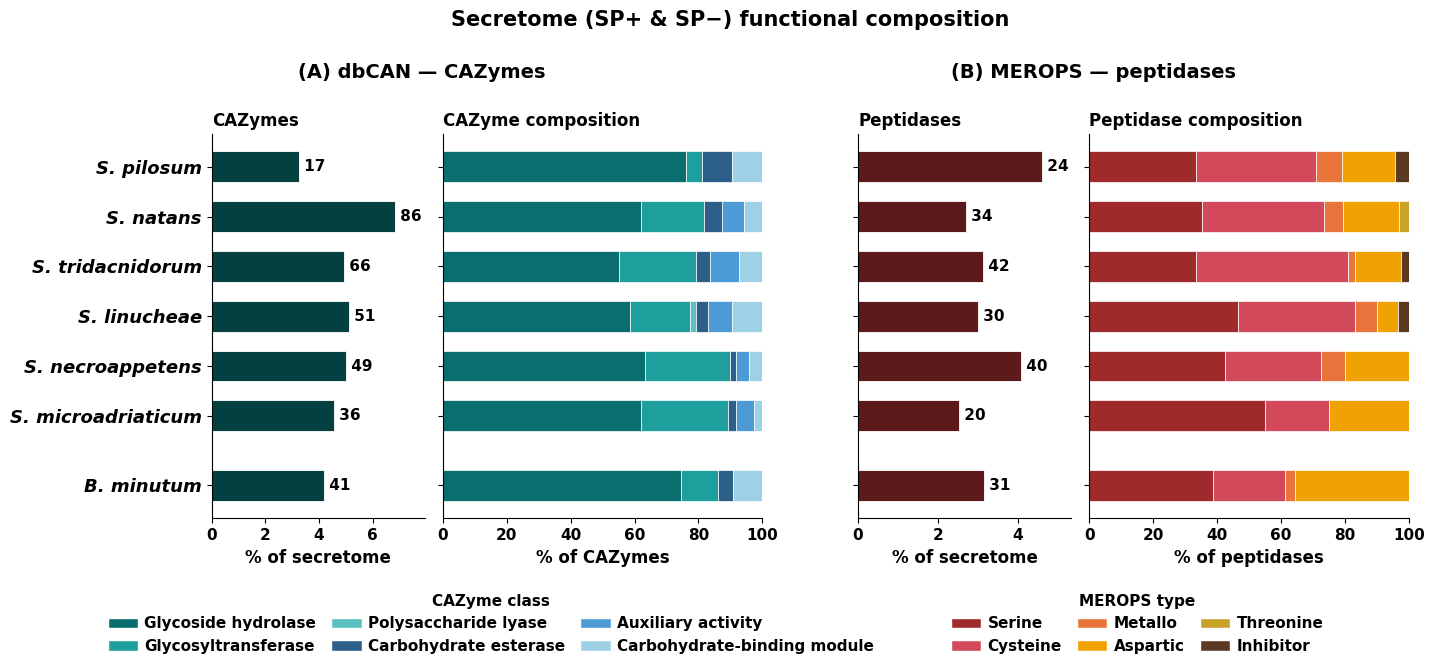

In [4]:
# ============================================================
# Combined secretome (SP+ ∪ SP−) — magnitude + composition
# Per DB: [total % of secretome | class composition (% of DB proteins)]
# 4 bar-columns, species shared on y (clade gap before Bmin)
# ============================================================
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Patch

DBCAN_DIR  = os.path.join(BASE, "12_db_functional_classes", "dbcan_out")
MEROPS_DIR = os.path.join(BASE, "12_db_functional_classes", "merops_out")
OUT_DIR    = os.path.join(BASE, "Publication", "figures_pre")
os.makedirs(OUT_DIR, exist_ok=True)

STRAIN_ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
KEEP = set(STRAIN_ORDER)
GENUS = {"Spil":"Symbiodinium","Snat":"Symbiodinium","Stri":"Symbiodinium",
         "Slin":"Symbiodinium","Snec":"Symbiodinium","Smic":"Symbiodinium","Bmin":"Breviolum"}
SPECIES = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
           "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
           "Bmin":"B. minutum"}

CAZY_CLASSES = ["GH","GT","PL","CE","AA","CBM"]
CLASS_NAME = {"GH":"Glycoside hydrolase", "GT":"Glycosyltransferase",
              "PL":"Polysaccharide lyase", "CE":"Carbohydrate esterase",
              "AA":"Auxiliary activity", "CBM":"Carbohydrate-binding module"}
CLASS_COLOR  = {"GH":"#0B6E6E","GT":"#1F9E9E","PL":"#5BC0BE",
                "CE":"#2C5F8A","AA":"#4C9BD6","CBM":"#9ED0E6"}
CAZ_RE = re.compile(r'\b(GH|GT|PL|CE|AA|CBM)\d+')
MAG_CAZ = "#04403F"

CAT_TYPES = ["S","C","M","A","T","G","N","P","U","I"]
CAT_NAME  = {"S":"Serine","C":"Cysteine","M":"Metallo","A":"Aspartic","T":"Threonine",
             "G":"Glutamic","N":"Asparagine","P":"Mixed","U":"Unknown","I":"Inhibitor"}
CAT_COLOR = {"S":"#9E2A2B","C":"#D1495B","M":"#E8743B","A":"#F0A202","T":"#C9A227",
             "G":"#7B4B94","N":"#B08BBA","P":"#8C6A5D","U":"#C7B8A1","I":"#5C3A21"}
MER_RE = re.compile(r'\b([ASCGMNPTUI]\d{2})\.\d{3}\b')
MAG_MER = "#5C1A1B"

def canon_strain(raw):
    if raw.startswith("Smic"): return "Smic"
    for s in STRAIN_ORDER:
        if raw == s or raw.startswith(s + "_") or raw.startswith(s): return s
    return raw
def detect_category(fname):
    low = fname.lower()
    if re.search(r'sp[_\-]?pos|_pos_|sppos', low): return "SP+"
    if re.search(r'sp[_\-]?neg|_neg_|spneg', low): return "SP−"
    return None
def count_fasta(path):
    n = 0
    with open(path) as fh:
        for line in fh:
            if line.startswith(">"): n += 1
    return n
def find_uniinput(folder):
    for pat in ("uniInput","uniInput.faa","uniInput.fasta","*uniInput*","*.faa"):
        hits = [h for h in glob.glob(os.path.join(folder, "**", pat), recursive=True)
                if os.path.isfile(h)]
        if hits: return sorted(hits, key=len)[0]
    return None
def find_overview(folder):
    for pat in ("overview.tsv","overview.txt","*overview*.tsv","*overview*.txt"):
        hits = glob.glob(os.path.join(folder, "**", pat), recursive=True)
        if hits: return sorted(hits)[0]
    return None

def parse_overview(path):
    df = pd.read_csv(path, sep="\t", dtype=str).fillna("")
    if df.shape[1] == 1: df = pd.read_csv(path, dtype=str).fillna("")
    cols = list(df.columns)
    gene_col   = next((c for c in cols if "gene" in c.lower()), cols[0])
    tool_cols  = [c for c in cols if c.lower().replace("-","_") in
                  ("hmmer","dbcan_sub","ecami","hotpep","diamond")]
    ntools_col = next((c for c in cols if "tool" in c.lower()), None)
    search_cols = tool_cols if tool_cols else [c for c in cols if c != gene_col]
    counts = {c: 0 for c in CAZY_CLASSES}; n_prot = 0
    for _, r in df.iterrows():
        if ntools_col:
            digits = re.sub(r"[^0-9]", "", str(r[ntools_col])); n = int(digits) if digits else 0
        else:
            n = sum(1 for c in tool_cols
                    if str(r[c]).strip() not in ("-","") and CAZ_RE.search(str(r[c])))
        if n < 2: continue
        classes = {m.group(1) for c in search_cols for m in CAZ_RE.finditer(str(r[c]))}
        if classes:
            n_prot += 1
            for c in classes: counts[c] += 1
    return n_prot, counts

def parse_merops(path):
    df = pd.read_csv(path, sep="\t", header=None, dtype=str, comment="#").fillna("")
    if df.shape[1] < 2: return 0, {t:0 for t in CAT_TYPES}
    q = df.columns[0]
    eval_col = None
    for c in df.columns[1:]:
        s = df[c].head(50)
        if s.str.match(r'^\d*\.?\d+([eE][-+]?\d+)?$').mean() > 0.8 and s.str.contains('e',case=False).any():
            eval_col = c; break
    if eval_col is None and df.shape[1] >= 11: eval_col = 10
    best = {}
    for _, r in df.iterrows():
        fam = None
        for c in df.columns[1:]:
            mm = MER_RE.search(str(r[c]))
            if mm: fam = mm.group(1); break
        if not fam: continue
        ev = 1.0
        if eval_col is not None:
            try: ev = float(r[eval_col])
            except Exception: ev = 1.0
        qid = r[q]
        if qid not in best or ev < best[qid][1]: best[qid] = (fam[0], ev)
    counts = {t: 0 for t in CAT_TYPES}
    for letter, _ in best.values():
        if letter in counts: counts[letter] += 1
    return len(best), counts

# ---- collect per (strain, cat) then AGGREGATE across cats ----
db_raw, denom_raw = [], []
for folder in sorted(glob.glob(os.path.join(DBCAN_DIR, "*_SP_*_secretome_final"))):
    name = os.path.basename(folder)
    if "headerback" in name: continue
    m = re.search(r'_SP_(pos|neg)_secretome_final$', name)
    if not m: continue
    cat = "SP+" if m.group(1)=="pos" else "SP−"
    strain = canon_strain(name[:m.start()])
    if strain not in KEEP: continue
    ov = find_overview(folder)
    if not ov: continue
    n_, counts = parse_overview(ov)
    uni = find_uniinput(folder); denom = count_fasta(uni) if uni else 0
    db_raw.append((strain, cat, name, n_, counts, denom))

# dedup per (strain,cat) preferring Smic_jgi
db_cat, denom_cat = {}, {}
for (strain, cat), grp in pd.DataFrame(
        db_raw, columns=["strain","cat","folder","n","counts","denom"]).groupby(["strain","cat"]):
    g = grp
    if strain == "Smic":
        j = g[g.folder.str.startswith("Smic_jgi")]; g = j if not j.empty else g
    row = g.sort_values("folder").iloc[0]
    db_cat[(strain,cat)] = (row["n"], row["counts"]); denom_cat[(strain,cat)] = row["denom"]

me_raw = []
for p in sorted(glob.glob(os.path.join(MEROPS_DIR, "*"))):
    if os.path.isdir(p): continue
    fname = os.path.basename(p)
    strain = canon_strain(fname)
    if strain is None or strain not in KEEP: continue
    cat = detect_category(fname)
    if cat is None: continue
    n_, counts = parse_merops(p)
    me_raw.append((strain, cat, fname, n_, counts))
me_cat = {}
for (strain, cat), grp in pd.DataFrame(
        me_raw, columns=["strain","cat","folder","n","counts"]).groupby(["strain","cat"]):
    g = grp
    if strain == "Smic":
        j = g[g.folder.str.startswith("Smic_jgi")]; g = j if not j.empty else g
    row = g.sort_values("folder").iloc[0]
    me_cat[(strain,cat)] = (row["n"], row["counts"])

# aggregate SP+ ∪ SP− (disjoint sets → sum)
db_agg, me_agg, secretome = {}, {}, {}
for s in STRAIN_ORDER:
    dn = sum(denom_cat.get((s,c),0) for c in ("SP+","SP−"))
    if dn: secretome[s] = dn
    # dbCAN
    n_tot = sum(db_cat.get((s,c),(0,{}))[0] for c in ("SP+","SP−"))
    cc = {c:0 for c in CAZY_CLASSES}
    for cat in ("SP+","SP−"):
        for c,v in db_cat.get((s,cat),(0,{}))[1].items(): cc[c]+=v
    if n_tot: db_agg[s] = (n_tot, cc)
    # MEROPS
    m_tot = sum(me_cat.get((s,c),(0,{}))[0] for c in ("SP+","SP−"))
    mm = {t:0 for t in CAT_TYPES}
    for cat in ("SP+","SP−"):
        for t,v in me_cat.get((s,cat),(0,{}))[1].items(): mm[t]+=v
    if m_tot: me_agg[s] = (m_tot, mm)

present = [s for s in STRAIN_ORDER if s in secretome]
print("Combined secretome sizes (SP+ ∪ SP−):")
for s in present:
    dn = secretome[s]
    print(f"  {s:5s}: {dn:5d} | CAZymes {db_agg.get(s,(0,{}))[0]:3d} "
          f"({db_agg.get(s,(0,{}))[0]/dn*100:4.1f}%) | "
          f"peptidases {me_agg.get(s,(0,{}))[0]:3d} ({me_agg.get(s,(0,{}))[0]/dn*100:4.1f}%)")

# ---- y layout (Spil top -> Bmin bottom, clade gap) ----------
GAP, base_y, y, gap_done = 0.4, {}, 0.0, False
for s in present:
    if GENUS[s] != "Symbiodinium" and not gap_done:
        y += GAP; gap_done = True
    base_y[s] = y; y += 1.0

# ---- figure ------------------------------------------------
rcParams.update({"font.weight":"bold","axes.labelweight":"bold",
                 "axes.titleweight":"bold","font.size":13,
                 "savefig.dpi":600,"pdf.fonttype":42,"ps.fonttype":42})

fig = plt.figure(figsize=(14, 6.2))
gs = fig.add_gridspec(1, 5, width_ratios=[1.0, 1.5, 0.28, 1.0, 1.5], wspace=0.08)
axDbMag  = fig.add_subplot(gs[0])
axDbComp = fig.add_subplot(gs[1], sharey=axDbMag)
axMeMag  = fig.add_subplot(gs[3], sharey=axDbMag)
axMeComp = fig.add_subplot(gs[4], sharey=axDbMag)
BAR_H = 0.62

def draw_mag(ax, agg, color, unit):
    xmax = 0
    for s in present:
        if s not in agg: continue
        n = agg[s][0]; pct = n/secretome[s]*100
        ax.barh(base_y[s], pct, height=BAR_H, color=color, edgecolor="white", linewidth=0.6)
        ax.text(pct, base_y[s], f" {n}", va="center", ha="left",
                fontsize=11, fontweight="bold")
        xmax = max(xmax, pct)
    ax.set_xlim(0, xmax*1.16)
    ax.set_xlabel(f"% of secretome", fontweight="bold", fontsize=12)

def draw_comp(ax, agg, classes, color_map, denom_label):
    for s in present:
        if s not in agg: continue
        counts = agg[s][1]; tot = sum(counts.values())
        if tot == 0: continue
        left = 0
        for c in classes:
            pct = counts.get(c,0)/tot*100
            if pct > 0:
                ax.barh(base_y[s], pct, height=BAR_H, left=left,
                        color=color_map[c], edgecolor="white", linewidth=0.5)
                left += pct
    ax.set_xlim(0, 100)
    ax.set_xlabel(f"% of {denom_label}", fontweight="bold", fontsize=12)

draw_mag(axDbMag, db_agg, MAG_CAZ, "CAZymes")
draw_comp(axDbComp, db_agg, CAZY_CLASSES, CLASS_COLOR, "CAZymes")
draw_mag(axMeMag, me_agg, MAG_MER, "peptidases")
draw_comp(axMeComp, me_agg, CAT_TYPES, CAT_COLOR, "peptidases")

# titles / group headers
axDbMag.set_title("CAZymes", loc="left", fontsize=12, pad=6)
axDbComp.set_title("CAZyme composition", loc="left", fontsize=12, pad=6)
axMeMag.set_title("Peptidases", loc="left", fontsize=12, pad=6)
axMeComp.set_title("Peptidase composition", loc="left", fontsize=12, pad=6)
fig.text(0.28, 0.95, "(A) dbCAN — CAZymes", ha="center", fontsize=14, fontweight="bold")
fig.text(0.76, 0.95, "(B) MEROPS — peptidases", ha="center", fontsize=14, fontweight="bold")

# species y-axis (leftmost only), plain italic, Spil at top
axDbMag.set_yticks([base_y[s] for s in present])
axDbMag.set_yticklabels([SPECIES[s] for s in present], fontstyle="italic", fontsize=13)
axDbMag.invert_yaxis()
for ax in (axDbComp, axMeMag, axMeComp):
    ax.tick_params(labelleft=False)
for ax in (axDbMag, axDbComp, axMeMag, axMeComp):
    ax.spines[["top","right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=11)

# legends under each pair
caz_present = [c for c in CAZY_CLASSES if any(db_agg.get(s,(0,{}))[1].get(c,0)>0 for s in present)]
legA = [Patch(facecolor=CLASS_COLOR[c], edgecolor="white", label=CLASS_NAME[c]) for c in caz_present]
axDbComp.legend(handles=legA, title="CAZyme class", ncol=min(3,len(legA) or 1),
                loc="upper center", bbox_to_anchor=(0.15, -0.16), frameon=False,
                fontsize=11, title_fontsize=11, columnspacing=1.0, handletextpad=0.4)
mer_present = [t for t in CAT_TYPES if any(me_agg.get(s,(0,{}))[1].get(t,0)>0 for s in present)]
legB = [Patch(facecolor=CAT_COLOR[t], edgecolor="white", label=CAT_NAME[t]) for t in mer_present]
axMeComp.legend(handles=legB, title="MEROPS type", ncol=min(3,len(legB) or 1),
                loc="upper center", bbox_to_anchor=(0.15, -0.16), frameon=False,
                fontsize=11, title_fontsize=11, columnspacing=1.0, handletextpad=0.4)

fig.suptitle("Secretome (SP+ & SP−) functional composition",
             fontweight="bold", y=1.06, fontsize=15)
fig.subplots_adjust(top=0.86, bottom=0.24, left=0.13, right=0.985)

stem = os.path.join(OUT_DIR, "combined_secretome_dbcan_merops_composition")
for ext in ("pdf","svg","png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("\nSaved:", stem + ".{pdf,svg,png}")
plt.show()

# CAZyme family-level presence

SP+: 80×7 | SP−: 33×7 | gmax=8 | flat bin 1–3, 5 gradient bins
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/dbcan_cazyme_family_abundance_A_SPpos.{pdf,svg,png}


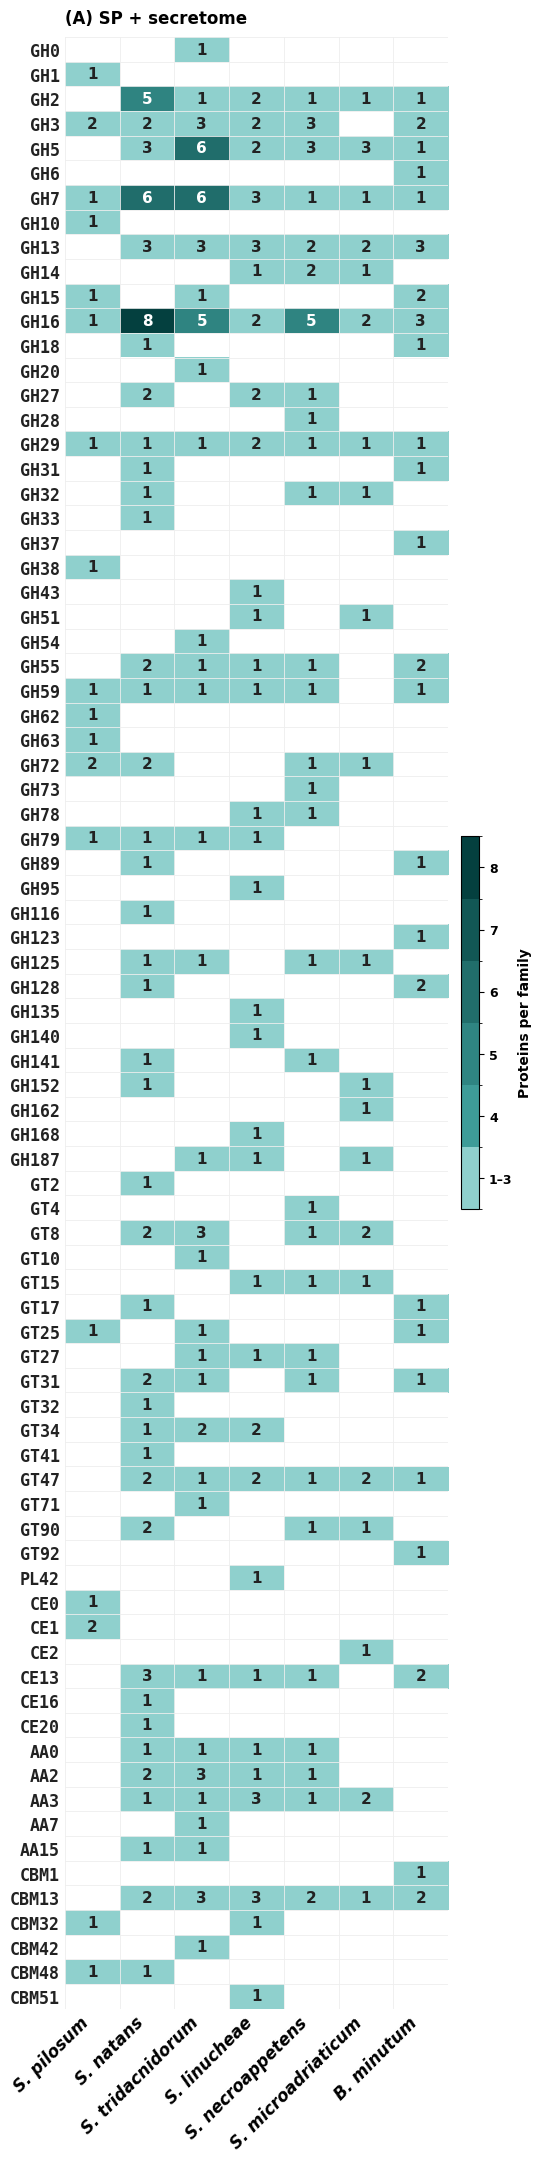

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/dbcan_cazyme_family_abundance_B_SPneg.{pdf,svg,png}


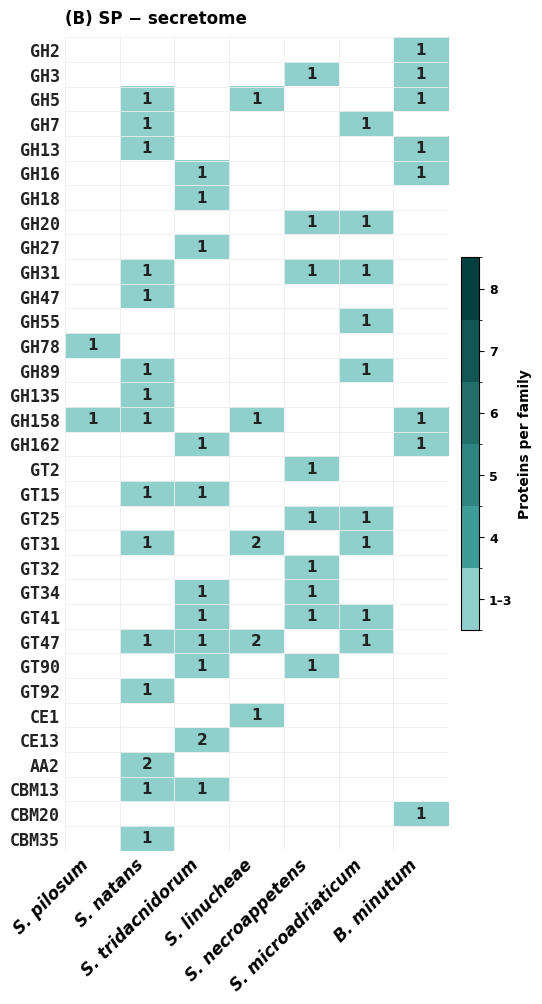

In [6]:
# ============================================================
# CAZyme FAMILY abundance map — SP+ (A) and SP− (B), shared scale
# counts 1–3 = one flat color; counts >3 = gradient; absent = white
# ============================================================
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm

# ---- options -----------------------------------------------
MIN_TOTAL   = 1
MIN_SPECIES = 1
FLAT_MAX    = 3            # counts 1..FLAT_MAX share one flat color; >FLAT_MAX ramp

DBCAN_DIR = os.path.join(BASE, "12_db_functional_classes", "dbcan_out")
OUT_DIR   = os.path.join(BASE, "Publication", "figures_pre")
os.makedirs(OUT_DIR, exist_ok=True)

STRAIN_ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
KEEP = set(STRAIN_ORDER)
SPECIES = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
           "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
           "Bmin":"B. minutum"}

CAZY_CLASSES = ["GH","GT","PL","CE","AA","CBM"]
CAZ_RE  = re.compile(r'\b(GH|GT|PL|CE|AA|CBM)\d+')
FAM_RE  = re.compile(r'\b((GH|GT|PL|CE|AA|CBM)\d+)')

def canon_strain(raw):
    if raw.startswith("Smic"): return "Smic"
    for s in STRAIN_ORDER:
        if raw == s or raw.startswith(s + "_") or raw.startswith(s): return s
    return raw

def find_overview(folder):
    for pat in ("overview.tsv","overview.txt","*overview*.tsv","*overview*.txt"):
        hits = glob.glob(os.path.join(folder, "**", pat), recursive=True)
        if hits: return sorted(hits)[0]
    return None

def parse_overview_families(path):
    df = pd.read_csv(path, sep="\t", dtype=str).fillna("")
    if df.shape[1] == 1: df = pd.read_csv(path, dtype=str).fillna("")
    cols = list(df.columns)
    gene_col   = next((c for c in cols if "gene" in c.lower()), cols[0])
    tool_cols  = [c for c in cols if c.lower().replace("-","_") in
                  ("hmmer","dbcan_sub","ecami","hotpep","diamond")]
    ntools_col = next((c for c in cols if "tool" in c.lower()), None)
    search_cols = tool_cols if tool_cols else [c for c in cols if c != gene_col]
    fam_counts = {}
    for _, r in df.iterrows():
        if ntools_col:
            digits = re.sub(r"[^0-9]", "", str(r[ntools_col])); n = int(digits) if digits else 0
        else:
            n = sum(1 for c in tool_cols
                    if str(r[c]).strip() not in ("-","") and CAZ_RE.search(str(r[c])))
        if n < 2: continue
        fams = {m.group(1) for c in search_cols for m in FAM_RE.finditer(str(r[c]))}
        for f in fams: fam_counts[f] = fam_counts.get(f, 0) + 1
    return fam_counts

def fam_key(f):
    cls = re.match(r'[A-Z]+', f).group(0)
    num = int(re.search(r'\d+', f).group(0))
    return (CAZY_CLASSES.index(cls) if cls in CAZY_CLASSES else 99, num)

# ---- collect per category (dedup, prefer Smic_jgi) ---------
def collect(category):
    raw = []
    for folder in sorted(glob.glob(os.path.join(DBCAN_DIR, "*_SP_*_secretome_final"))):
        name = os.path.basename(folder)
        if "headerback" in name: continue
        m = re.search(r'_SP_(pos|neg)_secretome_final$', name)
        if not m: continue
        if ("SP+" if m.group(1)=="pos" else "SP−") != category: continue
        strain = canon_strain(name[:m.start()])
        if strain not in KEEP: continue
        ov = find_overview(folder)
        if not ov: print(f"[warn] no overview in {name}"); continue
        raw.append((strain, name, parse_overview_families(ov)))
    best = {}
    for strain, grp in pd.DataFrame(raw, columns=["strain","folder","fam"]).groupby("strain"):
        g = grp
        if strain == "Smic":
            j = g[g.folder.str.startswith("Smic_jgi")]; g = j if not j.empty else g
        best[strain] = g.sort_values("folder").iloc[0]["fam"]
    present = [s for s in STRAIN_ORDER if s in best]
    fams = sorted({f for s in present for f in best[s]}, key=fam_key)
    mat = pd.DataFrame(0, index=fams, columns=present)
    for s in present:
        for f, c in best[s].items(): mat.loc[f, s] = c
    tot = mat.sum(axis=1); nsp = (mat > 0).sum(axis=1)
    mat = mat[(tot >= MIN_TOTAL) & (nsp >= MIN_SPECIES)]
    return present, mat

# ---- collect both, then build a SHARED norm/cmap -----------
presentA, matA = collect("SP+")
presentB, matB = collect("SP−")
gmax = int(max(matA.values.max() if matA.size else 1,
               matB.values.max() if matB.size else 1))
gmax = max(gmax, FLAT_MAX + 1)          # ensure at least one gradient bin

# boundaries: [0.5 .. FLAT_MAX+0.5] = flat bin, then one bin per integer up to gmax
bounds = [0.5, FLAT_MAX + 0.5] + [x + 0.5 for x in range(FLAT_MAX + 1, gmax + 1)]
n_grad = len(bounds) - 2                 # gradient bins above the flat bin
# colors: flat teal for the 1..FLAT_MAX bin, then a ramp up to deep teal
FLAT_COLOR = "#8FD0CD"
ramp = LinearSegmentedColormap.from_list("caz_ramp", ["#3E9C98", "#04403F"])
grad_colors = [ramp(i / max(1, n_grad - 1)) for i in range(n_grad)]
from matplotlib.colors import ListedColormap, to_rgba
cmap = ListedColormap([to_rgba(FLAT_COLOR)] + grad_colors)
cmap.set_bad(color="white")
norm = BoundaryNorm(bounds, cmap.N)

print(f"SP+: {matA.shape[0]}×{len(presentA)} | SP−: {matB.shape[0]}×{len(presentB)} | "
      f"gmax={gmax} | flat bin 1–{FLAT_MAX}, {n_grad} gradient bins")

# ---- figure builder ----------------------------------------
rcParams.update({"font.weight":"bold","axes.labelweight":"bold",
                 "axes.titleweight":"bold","font.size":12,
                 "savefig.dpi":600,"pdf.fonttype":42,"ps.fonttype":42})

def build_figure(mat, present, title, stem):
    n = mat.shape[0]
    order = list(reversed(list(mat.index)))
    ncol = len(present)
    fig_h = max(4.0, 0.30 * n + 2.0)
    fig, ax = plt.subplots(figsize=(5.6, fig_h))

    M = np.full((n, ncol), np.nan)
    for i, f in enumerate(order):
        for j, s in enumerate(present):
            v = int(mat.loc[f, s])
            if v > 0: M[i, j] = v
    Mm = np.ma.masked_invalid(M)
    im = ax.imshow(Mm, cmap=cmap, norm=norm, aspect="auto", origin="lower")

    for i in range(n):
        for j in range(ncol):
            v = M[i, j]
            if np.isnan(v): continue
            # dark text on the pale flat bin, white on the darker gradient bins
            txt_color = "#222222" if v <= FLAT_MAX else "white"
            ax.text(j, i, str(int(v)), ha="center", va="center",
                    fontsize=11, fontweight="bold", color=txt_color)

    ax.set_xlim(-0.5, ncol-0.5); ax.set_ylim(-0.5, n-0.5)
    ax.set_xticks(range(ncol))
    ax.set_xticklabels([SPECIES[s] for s in present], rotation=45, ha="right",
                       fontstyle="italic", fontsize=12)
    ax.set_yticks(range(n))
    ax.set_yticklabels(order, fontsize=12, fontfamily="monospace", color="#222222")
    ax.set_xticks(np.arange(-.5, ncol, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which="minor", color="#EEEEEE", linewidth=0.6)
    ax.tick_params(which="minor", length=0); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_aspect(0.45)
    ax.set_title(title, loc="left", fontweight="bold", fontsize=12, pad=10)

    cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03,
                        boundaries=bounds, spacing="uniform")
    # tick at flat-bin center + each gradient bin center
    centers = [(bounds[0]+bounds[1])/2] + [(bounds[k]+bounds[k+1])/2
                                           for k in range(1, len(bounds)-1)]
    labels  = [f"1–{FLAT_MAX}"] + [str(x) for x in range(FLAT_MAX+1, gmax+1)]
    cbar.set_ticks(centers); cbar.set_ticklabels(labels)
    cbar.set_label("Proteins per family", fontweight="bold", fontsize=10)
    cbar.ax.tick_params(labelsize=9)

    fig.subplots_adjust(left=0.16, right=0.90, top=0.95, bottom=0.16)
    for ext in ("pdf","svg","png"):
        fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
    print("Saved:", stem + ".{pdf,svg,png}")
    plt.show()

build_figure(matA, presentA, "(A) SP + secretome",
             os.path.join(OUT_DIR, "dbcan_cazyme_family_abundance_A_SPpos"))
build_figure(matB, presentB, "(B) SP − secretome",
             os.path.join(OUT_DIR, "dbcan_cazyme_family_abundance_B_SPneg"))

# MEROPS family-level heatmap

SP+: 24×7 | SP−: 16×7 | gmax=10 | flat bin 1–3, 7 gradient bins
Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/merops_peptidase_family_abundance_A_SPpos.{pdf,svg,png}


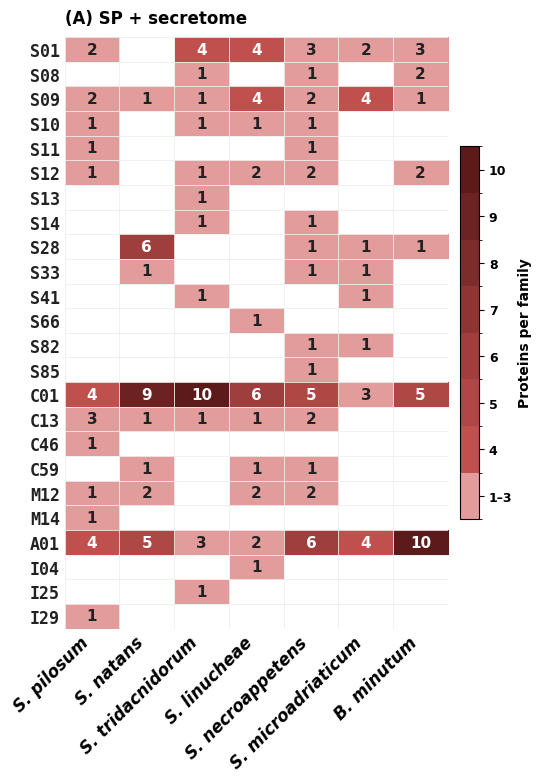

Saved: /content/drive/MyDrive/UTokyo/Proteome/Publication/figures_pre/merops_peptidase_family_abundance_B_SPneg.{pdf,svg,png}


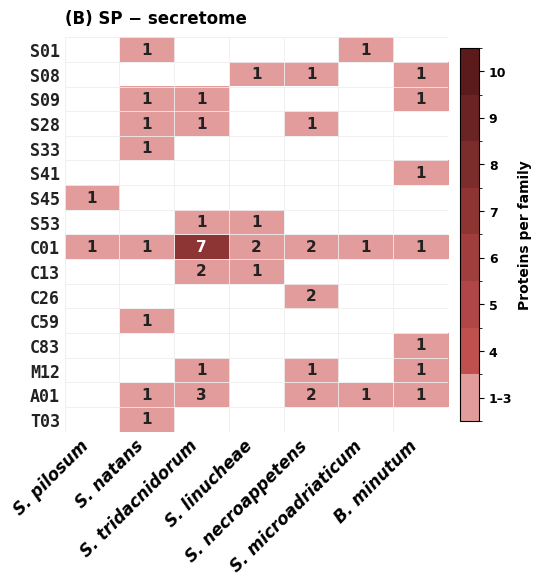

In [7]:
# ============================================================
# MEROPS FAMILY abundance map — SP+ (A) and SP− (B), shared scale
# counts 1–3 = one flat color; counts >3 = gradient; absent = white
# ============================================================
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm, ListedColormap, to_rgba

# ---- options -----------------------------------------------
MIN_TOTAL   = 1
MIN_SPECIES = 1
FLAT_MAX    = 3            # counts 1..FLAT_MAX share one flat color; >FLAT_MAX ramp

MEROPS_DIR = os.path.join(BASE, "12_db_functional_classes", "merops_out")
OUT_DIR    = os.path.join(BASE, "Publication", "figures_pre")
os.makedirs(OUT_DIR, exist_ok=True)

STRAIN_ORDER = ["Spil","Snat","Stri","Slin","Snec","Smic","Bmin"]
KEEP = set(STRAIN_ORDER)
SPECIES = {"Spil":"S. pilosum","Snat":"S. natans","Stri":"S. tridacnidorum",
           "Slin":"S. linucheae","Snec":"S. necroappetens","Smic":"S. microadriaticum",
           "Bmin":"B. minutum"}

CAT_TYPES = ["S","C","M","A","T","G","N","P","U","I"]
FAMCODE_RE = re.compile(r'\b([ASCGMNPTUI]\d{2})\.\d{3}\b')

def canon_strain(raw):
    if raw.startswith("Smic"): return "Smic"
    for s in STRAIN_ORDER:
        if raw == s or raw.startswith(s + "_") or raw.startswith(s): return s
    return raw

def detect_category(fname):
    low = fname.lower()
    if re.search(r'sp[_\-]?pos|_pos_|sppos', low): return "SP+"
    if re.search(r'sp[_\-]?neg|_neg_|spneg', low): return "SP−"
    return None

def best_hit_families(path):
    df = pd.read_csv(path, sep="\t", header=None, dtype=str, comment="#").fillna("")
    if df.shape[1] < 2: return {}
    q = df.columns[0]
    eval_col = None
    for c in df.columns[1:]:
        s = df[c].head(50)
        if s.str.match(r'^\d*\.?\d+([eE][-+]?\d+)?$').mean() > 0.8 and s.str.contains('e',case=False).any():
            eval_col = c; break
    if eval_col is None and df.shape[1] >= 11: eval_col = 10
    best = {}
    for _, r in df.iterrows():
        fam = None
        for c in df.columns[1:]:
            mm = FAMCODE_RE.search(str(r[c]))
            if mm: fam = mm.group(1); break
        if not fam: continue
        ev = 1.0
        if eval_col is not None:
            try: ev = float(r[eval_col])
            except Exception: ev = 1.0
        qid = r[q]
        if qid not in best or ev < best[qid][1]: best[qid] = (fam, ev)
    return {k: v[0] for k, v in best.items()}

def fam_key(f):
    letter = f[0]; num = int(f[1:])
    return (CAT_TYPES.index(letter) if letter in CAT_TYPES else 99, num)

# ---- collect per category (dedup, prefer Smic_jgi) ---------
def collect(category):
    raw = []
    for p in sorted(glob.glob(os.path.join(MEROPS_DIR, "*"))):
        if os.path.isdir(p): continue
        fname = os.path.basename(p)
        strain = canon_strain(fname)
        if strain is None or strain not in KEEP: continue
        if detect_category(fname) != category: continue
        fams = best_hit_families(p)
        if not fams: print(f"[warn] no family codes in {fname}"); continue
        fam_counts = {}
        for f in fams.values(): fam_counts[f] = fam_counts.get(f, 0) + 1
        raw.append((strain, fname, fam_counts))
    best = {}
    for strain, grp in pd.DataFrame(raw, columns=["strain","folder","fam"]).groupby("strain"):
        g = grp
        if strain == "Smic":
            j = g[g.folder.str.startswith("Smic_jgi")]; g = j if not j.empty else g
        best[strain] = g.sort_values("folder").iloc[0]["fam"]
    present = [s for s in STRAIN_ORDER if s in best]
    fams = sorted({f for s in present for f in best[s]}, key=fam_key)
    mat = pd.DataFrame(0, index=fams, columns=present)
    for s in present:
        for f, c in best[s].items(): mat.loc[f, s] = c
    tot = mat.sum(axis=1); nsp = (mat > 0).sum(axis=1)
    mat = mat[(tot >= MIN_TOTAL) & (nsp >= MIN_SPECIES)]
    return present, mat

# ---- collect both, then build a SHARED norm/cmap -----------
presentA, matA = collect("SP+")
presentB, matB = collect("SP−")
gmax = int(max(matA.values.max() if matA.size else 1,
               matB.values.max() if matB.size else 1))
gmax = max(gmax, FLAT_MAX + 1)

bounds = [0.5, FLAT_MAX + 0.5] + [x + 0.5 for x in range(FLAT_MAX + 1, gmax + 1)]
n_grad = len(bounds) - 2
FLAT_COLOR = "#E39C9C"                                   # pale warm (flat bin)
ramp = LinearSegmentedColormap.from_list("mer_ramp", ["#C0504E", "#5C1A1B"])
grad_colors = [ramp(i / max(1, n_grad - 1)) for i in range(n_grad)]
cmap = ListedColormap([to_rgba(FLAT_COLOR)] + grad_colors)
cmap.set_bad(color="white")
norm = BoundaryNorm(bounds, cmap.N)

print(f"SP+: {matA.shape[0]}×{len(presentA)} | SP−: {matB.shape[0]}×{len(presentB)} | "
      f"gmax={gmax} | flat bin 1–{FLAT_MAX}, {n_grad} gradient bins")

# ---- figure builder ----------------------------------------
rcParams.update({"font.weight":"bold","axes.labelweight":"bold",
                 "axes.titleweight":"bold","font.size":12,
                 "savefig.dpi":600,"pdf.fonttype":42,"ps.fonttype":42})

def build_figure(mat, present, title, stem):
    n = mat.shape[0]
    order = list(reversed(list(mat.index)))
    ncol = len(present)
    fig_h = max(4.0, 0.30 * n + 2.0)
    fig, ax = plt.subplots(figsize=(5.6, fig_h))

    M = np.full((n, ncol), np.nan)
    for i, f in enumerate(order):
        for j, s in enumerate(present):
            v = int(mat.loc[f, s])
            if v > 0: M[i, j] = v
    Mm = np.ma.masked_invalid(M)
    im = ax.imshow(Mm, cmap=cmap, norm=norm, aspect="auto", origin="lower")

    for i in range(n):
        for j in range(ncol):
            v = M[i, j]
            if np.isnan(v): continue
            txt_color = "#222222" if v <= FLAT_MAX else "white"
            ax.text(j, i, str(int(v)), ha="center", va="center",
                    fontsize=11, fontweight="bold", color=txt_color)

    ax.set_xlim(-0.5, ncol-0.5); ax.set_ylim(-0.5, n-0.5)
    ax.set_xticks(range(ncol))
    ax.set_xticklabels([SPECIES[s] for s in present], rotation=45, ha="right",
                       fontstyle="italic", fontsize=12)
    ax.set_yticks(range(n))
    ax.set_yticklabels(order, fontsize=12, fontfamily="monospace", color="#222222")
    ax.set_xticks(np.arange(-.5, ncol, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n, 1), minor=True)
    ax.grid(which="minor", color="#EEEEEE", linewidth=0.6)
    ax.tick_params(which="minor", length=0); ax.tick_params(length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_aspect(0.45)
    ax.set_title(title, loc="left", fontweight="bold", fontsize=12, pad=10)

    cbar = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03,
                        boundaries=bounds, spacing="uniform")
    centers = [(bounds[0]+bounds[1])/2] + [(bounds[k]+bounds[k+1])/2
                                           for k in range(1, len(bounds)-1)]
    labels  = [f"1–{FLAT_MAX}"] + [str(x) for x in range(FLAT_MAX+1, gmax+1)]
    cbar.set_ticks(centers); cbar.set_ticklabels(labels)
    cbar.set_label("Proteins per family", fontweight="bold", fontsize=10)
    cbar.ax.tick_params(labelsize=9)

    fig.subplots_adjust(left=0.16, right=0.90, top=0.95, bottom=0.16)
    for ext in ("pdf","svg","png"):
        fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
    print("Saved:", stem + ".{pdf,svg,png}")
    plt.show()

build_figure(matA, presentA, "(A) SP + secretome",
             os.path.join(OUT_DIR, "merops_peptidase_family_abundance_A_SPpos"))
build_figure(matB, presentB, "(B) SP − secretome",
             os.path.join(OUT_DIR, "merops_peptidase_family_abundance_B_SPneg"))